In [1]:
import rasterio, numpy as np, matplotlib, skimage
print("rasterio", rasterio.__version__)

rasterio 1.5.2


Day 1: Seeing Landslides from Space

- Tile centre (lat, lon): -1.61733, 29.49005
- Before image: 2023-01-07 (February to April scenes were cloudy or hazy over the tile)
- After image: 2023-07-21 (May and June were cloudy over the tile)
- Hand-label window: rows 83-183, columns 118-218 of the tile (100 × 100 pixels, window E)
- Labeling time: 25 minutes (hand-drawn in a Python notebook using a click tool)

## Part 1: Frame the problem

Q1. What turns heavy rain into a landslide?
The western and northern provinces and Kigali are steep and hilly. When days of heavy rain soak the ground, the water adds weight to the soil and weakens its grip on the slope, so it can give way and flow downhill. The reports describe rivers of mud sweeping through villages and rivers overflowing after the heavy rain

Q2. What does a fresh scar look like from above?
A fresh scar is a patch of bare brown or pale soil on a green slope, usually long and narrow in the downhill direction, with a sharp edge where the vegetation stops. Farmland is made of regular rectangular patches, a road is a thin line of constant width, and a cloud shadow is dark but the vegetation under it is still there. This is why NDVI should drop sharply on a scar

Q3. Who would use an automatic landslide map?
The emergency management ministry and local authorities could use it to decide which households in disaster-prone areas to move first, since the Local Government Minister told residents to leave those areas. The infrastructure ministry could use it to decide where to rebuild roads, bridges, schools and power lines, using the 110 billion Rwandan franc fund (about $98.5 million) to build stronger infrastructure.

Sources: The Sun/AFP, The Globe and Mail (AP)

In [2]:
import os, rasterio, numpy as np
import matplotlib.pyplot as plt

print(sorted(os.listdir("data")))

def read(path):
    with rasterio.open(path) as src:
        return src.read(1).astype("float32")

bands = {}
for date in ["before", "after"]:
    for b in ["B02", "B03", "B04", "B08"]:
        bands[(date, b)] = read(f"data/{date}_{b}.tiff")

for k, v in bands.items():
    print(k, v.shape, "min", v.min(), "max", v.max())

for date in ["before", "after"]:
    with rasterio.open(f"data/{date}_B04.tiff") as src:
        print(date, "CRS:", src.crs, "| size:", src.width, "x", src.height, "| dtype:", src.dtypes[0])

['after_B02.tiff', 'after_B03.tiff', 'after_B04.tiff', 'after_B08.tiff', 'before_B02.tiff', 'before_B03.tiff', 'before_B04.tiff', 'before_B08.tiff']
('before', 'B02') (267, 337) min 0.0056 max 0.7341
('before', 'B03') (267, 337) min 0.0134 max 0.7142
('before', 'B04') (267, 337) min 0.0113 max 0.7179
('before', 'B08') (267, 337) min 0.0 max 0.6548
('after', 'B02') (267, 337) min 0.0004 max 0.3235
('after', 'B03') (267, 337) min 0.0066 max 0.3419
('after', 'B04') (267, 337) min 0.0028 max 0.3583
('after', 'B08') (267, 337) min 0.0 max 0.6372
before CRS: EPSG:4326 | size: 337 x 267 | dtype: float32
after CRS: EPSG:4326 | size: 337 x 267 | dtype: float32


In [3]:
with rasterio.open("data/before_B04.tiff") as src:
    print("before:", src.width, "x", src.height, "| about", round(src.res[0] * 111320), "m")
with rasterio.open("data/after_B04.tiff") as src:
    print("after: ", src.width, "x", src.height, "| about", round(src.res[0] * 111320), "m")

before: 337 x 267 | about 10 m
after:  337 x 267 | about 10 m


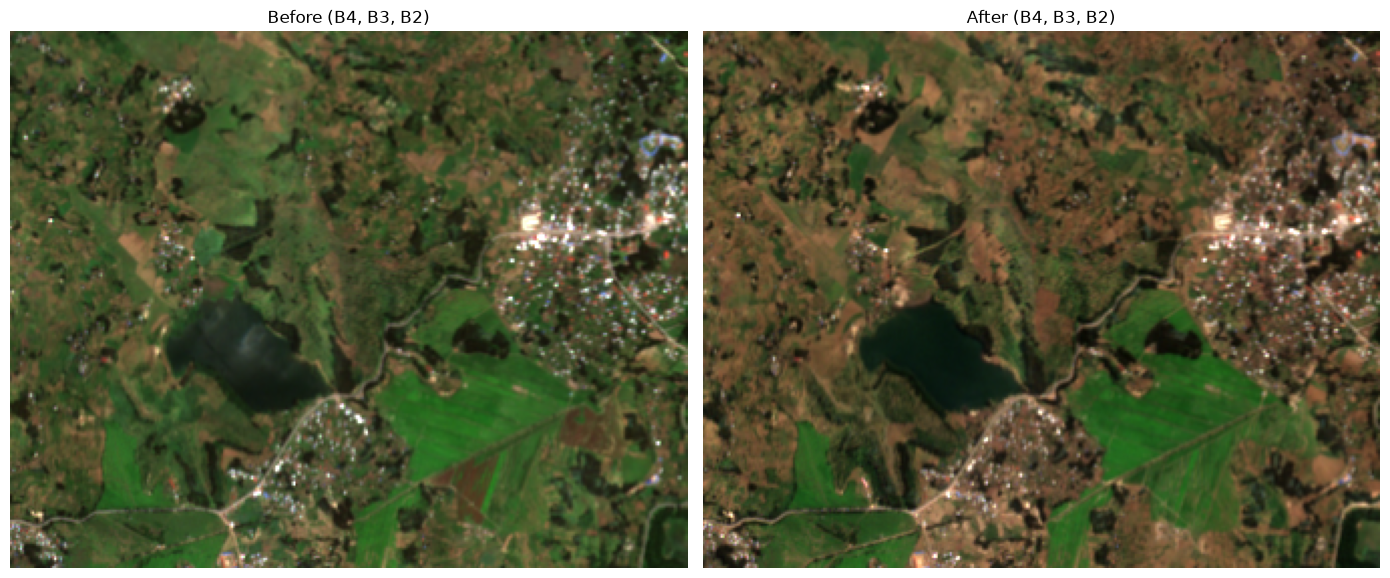

In [4]:
def true_colour(date):
    rgb = np.dstack([bands[(date, "B04")], bands[(date, "B03")], bands[(date, "B02")]])
    return np.clip(rgb / 0.2, 0, 1)    # brighten: reflectance 0.2 shows as full white

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, date in zip(axes, ["before", "after"]):
    ax.imshow(true_colour(date))
    ax.set_title(f"{date.capitalize()} (B4, B3, B2)")
    ax.axis("off")
plt.tight_layout()
plt.show()

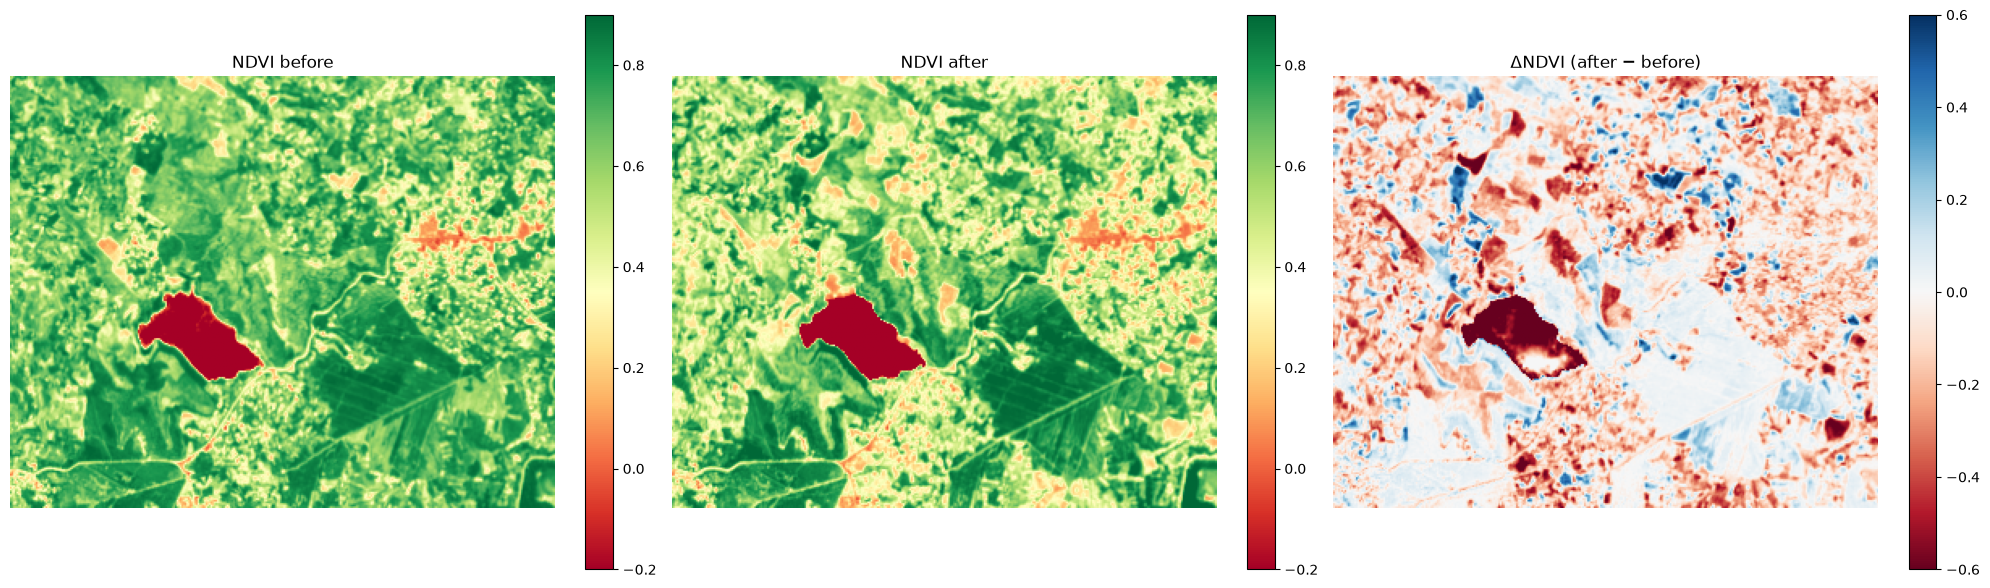

In [5]:
ndvi = lambda nir, red: (nir - red) / (nir + red + 1e-6)
ndvi_b = ndvi(bands[("before", "B08")], bands[("before", "B04")])
ndvi_a = ndvi(bands[("after", "B08")], bands[("after", "B04")])
dndvi = ndvi_a - ndvi_b

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
panels = [(ndvi_b, "NDVI before", "RdYlGn", -0.2, 0.9),
          (ndvi_a, "NDVI after", "RdYlGn", -0.2, 0.9),
          (dndvi, "ΔNDVI (after − before)", "RdBu", -0.6, 0.6)]
for ax, (img, title, cmap, lo, hi) in zip(axes, panels):
    im = ax.imshow(img, cmap=cmap, vmin=lo, vmax=hi)
    ax.set_title(title); ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

ΔNDVI mean: -0.08 | median: -0.054
Percentiles 1, 5, 10: [-0.668 -0.406 -0.304]


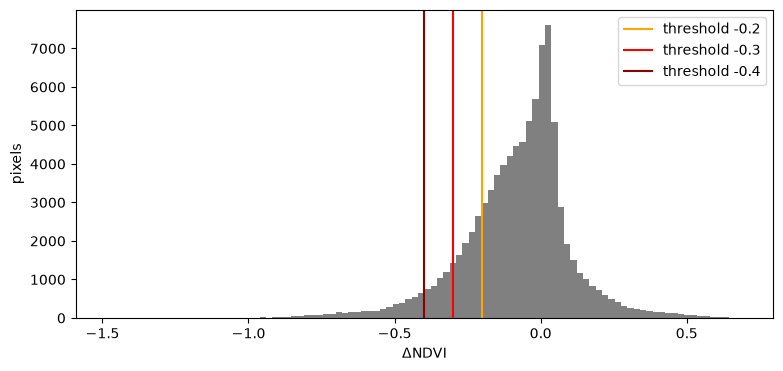

In [6]:
print("ΔNDVI mean:", dndvi.mean().round(3), "| median:", np.median(dndvi).round(3))
print("Percentiles 1, 5, 10:", np.percentile(dndvi, [1, 5, 10]).round(3))

plt.figure(figsize=(9, 4))
plt.hist(dndvi.ravel(), bins=100, color="grey")
for t, c in [(-0.2, "orange"), (-0.3, "red"), (-0.4, "darkred")]:
    plt.axvline(t, color=c, label=f"threshold {t}")
plt.xlabel("ΔNDVI"); plt.ylabel("pixels"); plt.legend(); plt.show()

Lost vegetation begins around ΔNDVI = -0.3, where the histogram leaves the main peak (centred near -0.05) and enters a thin left tail. A threshold of -0.2 sits inside the main peak and will pick up ordinary seasonal change.

T=-0.2: raw 18780 px (20.9%) -> with rule 15463 px (17.2%)
T=-0.3: raw 9287 px (10.3%) -> with rule 6853 px (7.6%)
T=-0.4: raw 4692 px (5.2%) -> with rule 2699 px (3.0%)


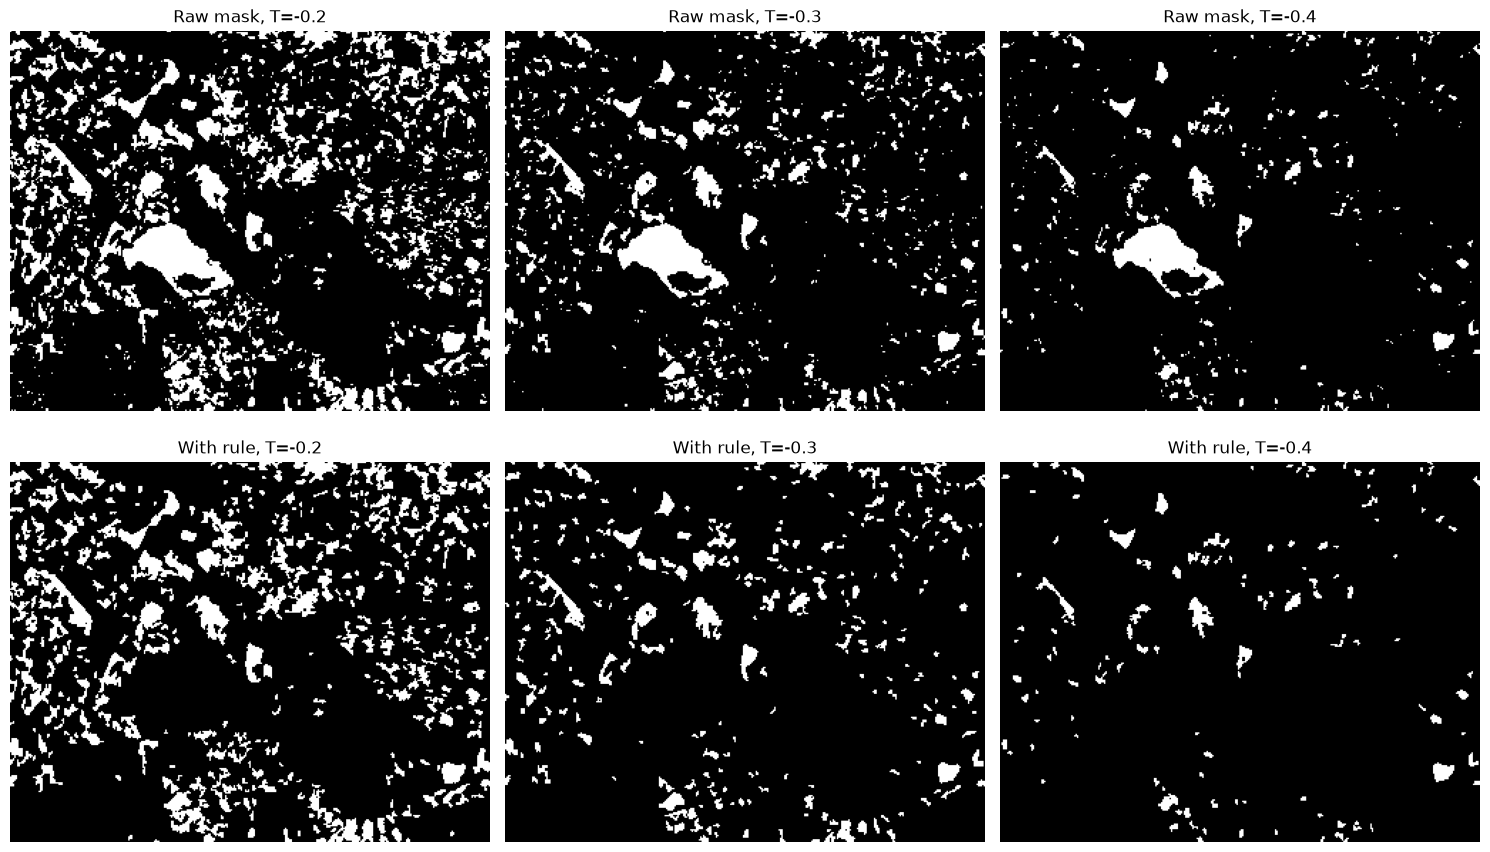

In [7]:
from skimage.morphology import remove_small_objects

def clean(m, min_px=5):
    try:
        return remove_small_objects(m.astype(bool), max_size=min_px - 1).astype("uint8")
    except TypeError:                      # older scikit-image
        return remove_small_objects(m.astype(bool), min_size=min_px).astype("uint8")

thresholds = [-0.2, -0.3, -0.4]
raw_masks   = {t: (dndvi < t).astype("uint8") for t in thresholds}
ruled_masks = {t: clean((dndvi < t) & (ndvi_b > 0.5)) for t in thresholds}   # extra rule

for t in thresholds:
    print(f"T={t}: raw {raw_masks[t].sum()} px ({raw_masks[t].mean():.1%}) "
          f"-> with rule {ruled_masks[t].sum()} px ({ruled_masks[t].mean():.1%})")

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for c, t in enumerate(thresholds):
    axes[0, c].imshow(raw_masks[t], cmap="gray");   axes[0, c].set_title(f"Raw mask, T={t}")
    axes[1, c].imshow(ruled_masks[t], cmap="gray"); axes[1, c].set_title(f"With rule, T={t}")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

My rule is: the pixel was vegetated before (NDVI_before > 0.5), and blobs under 5 pixels are removed. 

Weaknesses of a pixel rule

1. **It cannot tell why NDVI dropped.** A landslide, a harvested field, seasonal drying, cloud shadow and a new building all lower NDVI. The rule treats them the same. In my tile, even the strictest threshold (-0.4) flags 5.2% of pixels, and -0.2 flags 20.9%, far more than real scars could cover. The histogram shows the same thing: the main peak is shifted below zero, so ordinary seasonal change fills much of the area.

2. **It looks at each pixel alone.** A landslide scar is a long, narrow patch with sharp edges that runs downhill. The rule sees no shape, no texture and no neighbours, so it cannot separate a scar from a field of similar size. Removing blobs under 5 pixels is a crude fix that also deletes small real scars.

3. **One threshold for the whole tile.** No single number fits all land cover. At -0.2 many ordinary pixels pass (false positives). At -0.4 partly vegetated or small scars are missed (false negatives).

4. **It depends on the before image.** The NDVI_before > 0.5 rule removed 18% to 42% of the flagged pixels, depending on the threshold. This helps with water and bare ground, but it can also remove real scars on slopes that were only sparsely vegetated.

5. **The dates are six months apart.** My before image is from January and my after image is from July, because the cloudy rainy-season scenes were unusable. This adds crop cycles and seasonal browning that have nothing to do with landslides.

6. **Resolution is 10 m.** A scar narrower than one pixel mixes soil with vegetation and may not drop NDVI enough to cross the threshold.

7. **It has no terrain information.** Landslides happen on steep slopes, but the rule flags flat fields and valley floors just as easily. Slope data would help a model reject them.

*I will add the three real failure cases (false positive, false negative, uncertain) after Part 5.

### My extra rule

A pixel is flagged only if ΔNDVI is below the threshold **and** NDVI_before > 0.5 (the slope was vegetated in January). Blobs smaller than 5 pixels are then removed. The aim is to drop false alarms from water, buildings, bare ground and single noisy pixels.


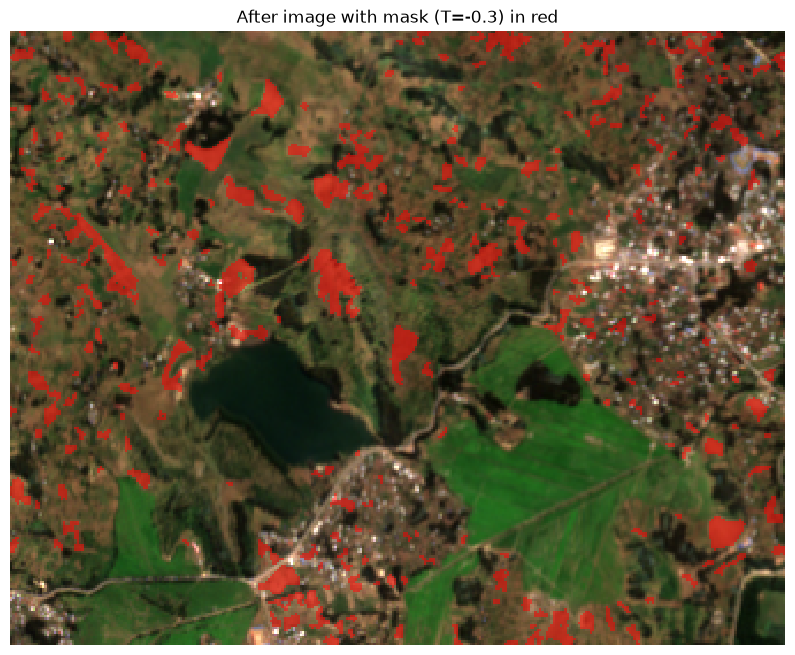

In [8]:
def true_colour(date, d=0.2):
    rgb = np.dstack([bands[(date, "B04")], bands[(date, "B03")], bands[(date, "B02")]])
    return np.clip(rgb / d, 0, 1)

BEST_T = -0.3          # change after Part 5 shows which threshold has the best IoU
overlay = true_colour("after").copy()
m = ruled_masks[BEST_T].astype(bool)
overlay[m] = 0.5 * overlay[m] + 0.5 * np.array([1, 0, 0])

plt.figure(figsize=(10, 8))
plt.imshow(overlay, interpolation="nearest")
plt.title(f"After image with mask (T={BEST_T}) in red"); plt.axis("off"); plt.show()

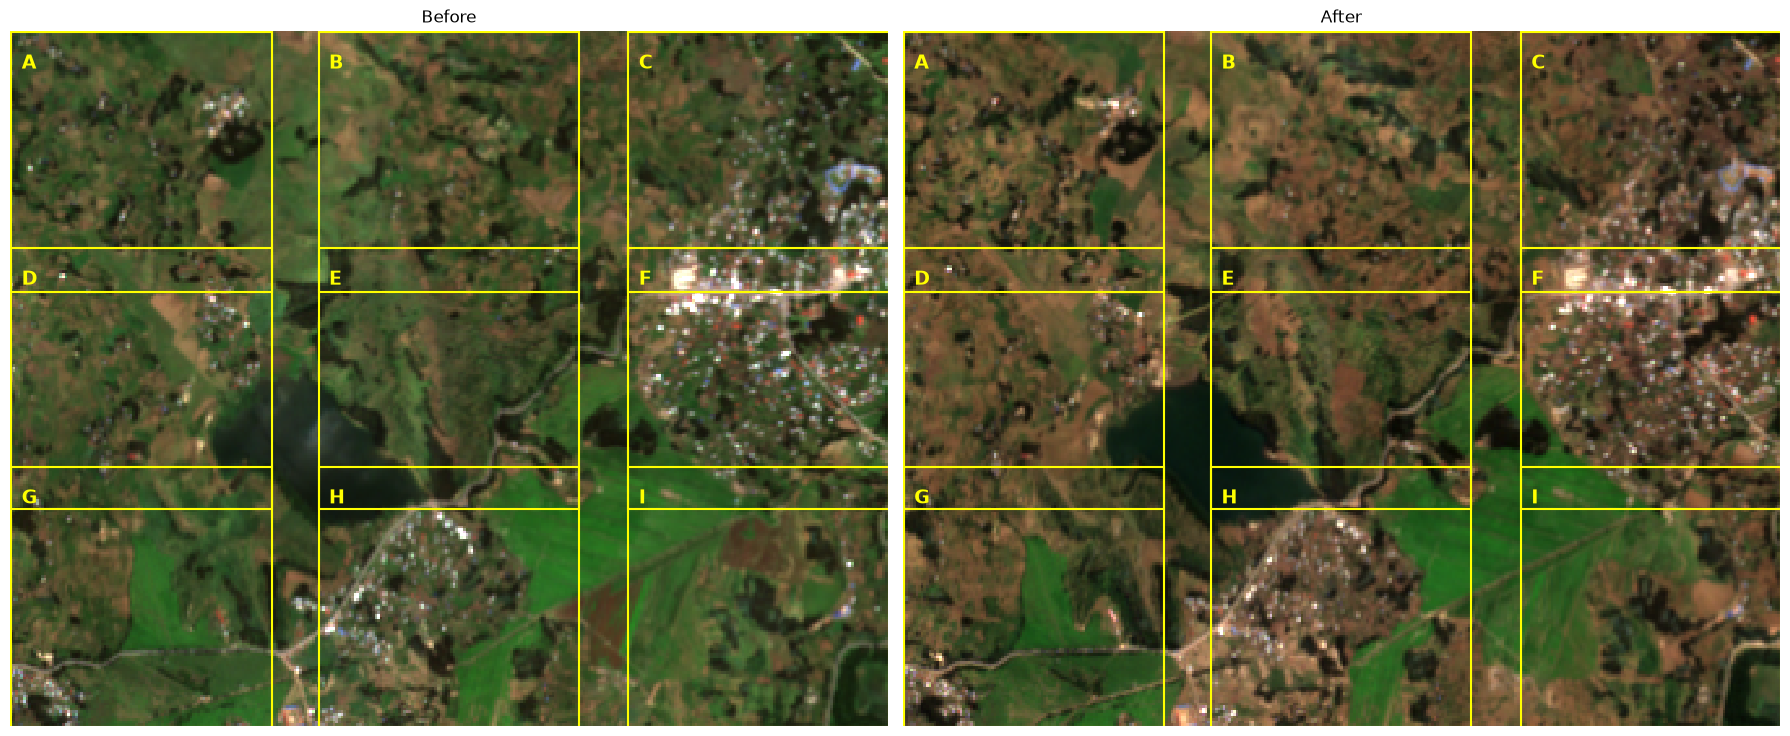

In [9]:
def true_colour(date, d=0.2):
    rgb = np.dstack([bands[(date, "B04")], bands[(date, "B03")], bands[(date, "B02")]])
    return np.clip(rgb / d, 0, 1)

import matplotlib.patches as patches
starts_r, starts_c = [0, 83, 167], [0, 118, 237]
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, date in zip(axes, ["before", "after"]):
    ax.imshow(true_colour(date), interpolation="nearest")
    k = 0
    for r in starts_r:
        for c in starts_c:
            ax.add_patch(patches.Rectangle((c, r), 100, 100, fill=False, ec="yellow", lw=1.5))
            ax.text(c + 4, r + 14, "ABCDEFGHI"[k], color="yellow", fontsize=14, weight="bold")
            k += 1
    ax.set_title(date.capitalize()); ax.axis("off")
plt.tight_layout(); plt.show()

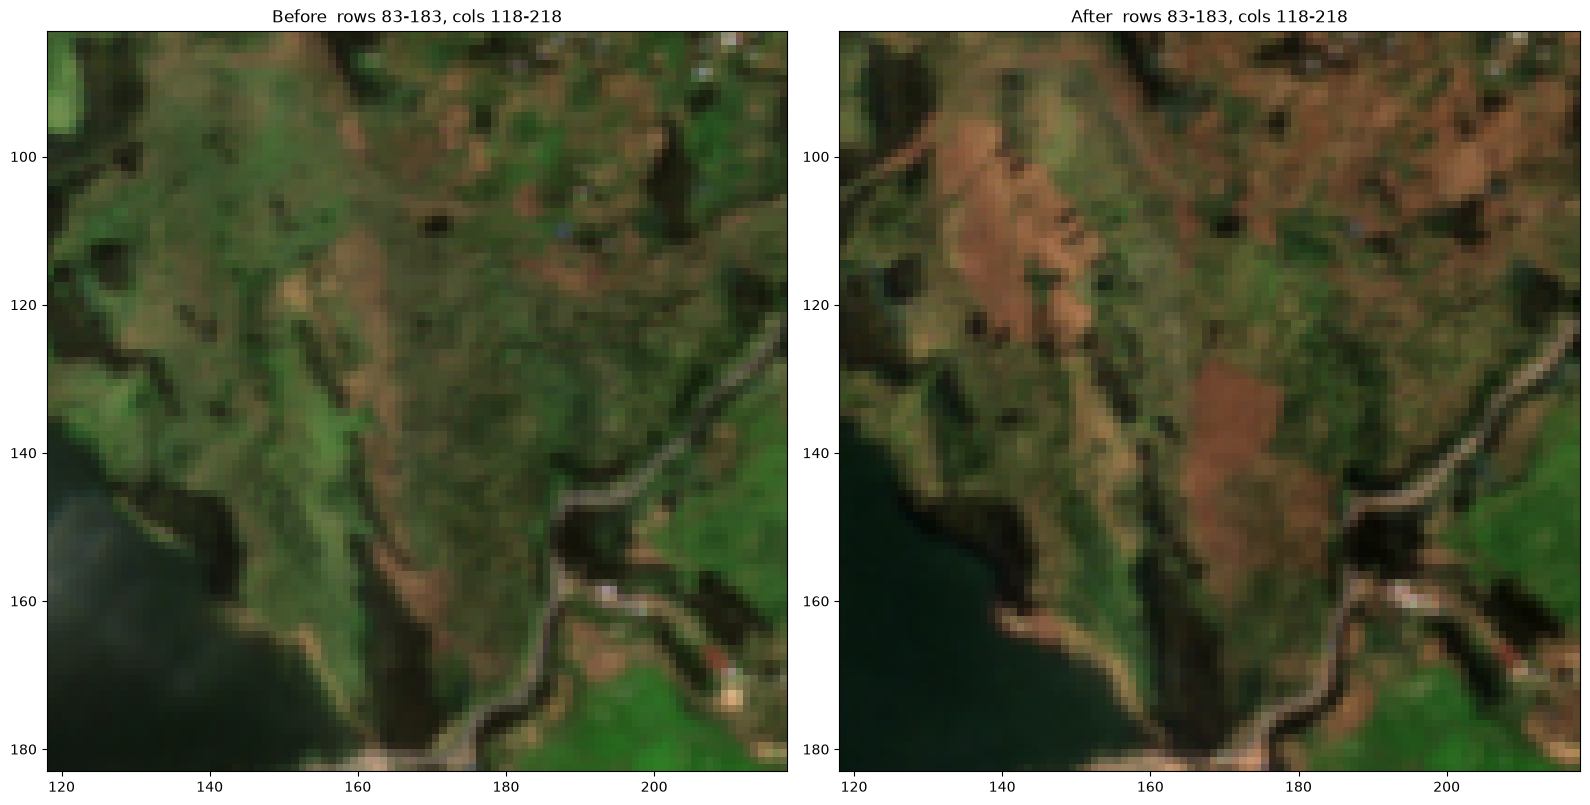

In [10]:
r0, c0 = 83, 118          # top-left corner of the window: change this for each candidate

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, date in zip(axes, ["before", "after"]):
    ax.imshow(true_colour(date)[r0:r0 + 100, c0:c0 + 100], interpolation="nearest",
              extent=(c0, c0 + 100, r0 + 100, r0))
    ax.set_title(f"{date.capitalize()}  rows {r0}-{r0+100}, cols {c0}-{c0+100}")
plt.tight_layout(); plt.show()

In [11]:
from rasterio.windows import Window

r0, c0 = 83, 118          # window E: change only if you choose another window
os.makedirs("out", exist_ok=True)

def save_crop(date):
    with rasterio.open(f"data/{date}_B04.tiff") as src:
        profile = src.profile.copy()
        transform = src.window_transform(Window(c0, r0, 100, 100))
    rgb = (true_colour(date)[r0:r0 + 100, c0:c0 + 100] * 255).astype("uint8")
    profile.update(count=3, dtype="uint8", width=100, height=100, transform=transform, nodata=None)
    with rasterio.open(f"out/{date}_window_rgb.tif", "w", **profile) as dst:
        dst.write(rgb.transpose(2, 0, 1))

for d in ["before", "after"]:
    save_crop(d)
print("saved:", os.listdir("out"))

saved: ['after_window_rgb.tif', 'before_window_rgb.tif']


In [12]:
import time
t_start = time.time()
print("Labeling started at", time.strftime("%H:%M:%S"))

Labeling started at 13:24:58


scars: 0 | labelled pixels: 0 | unsure pixels: 0


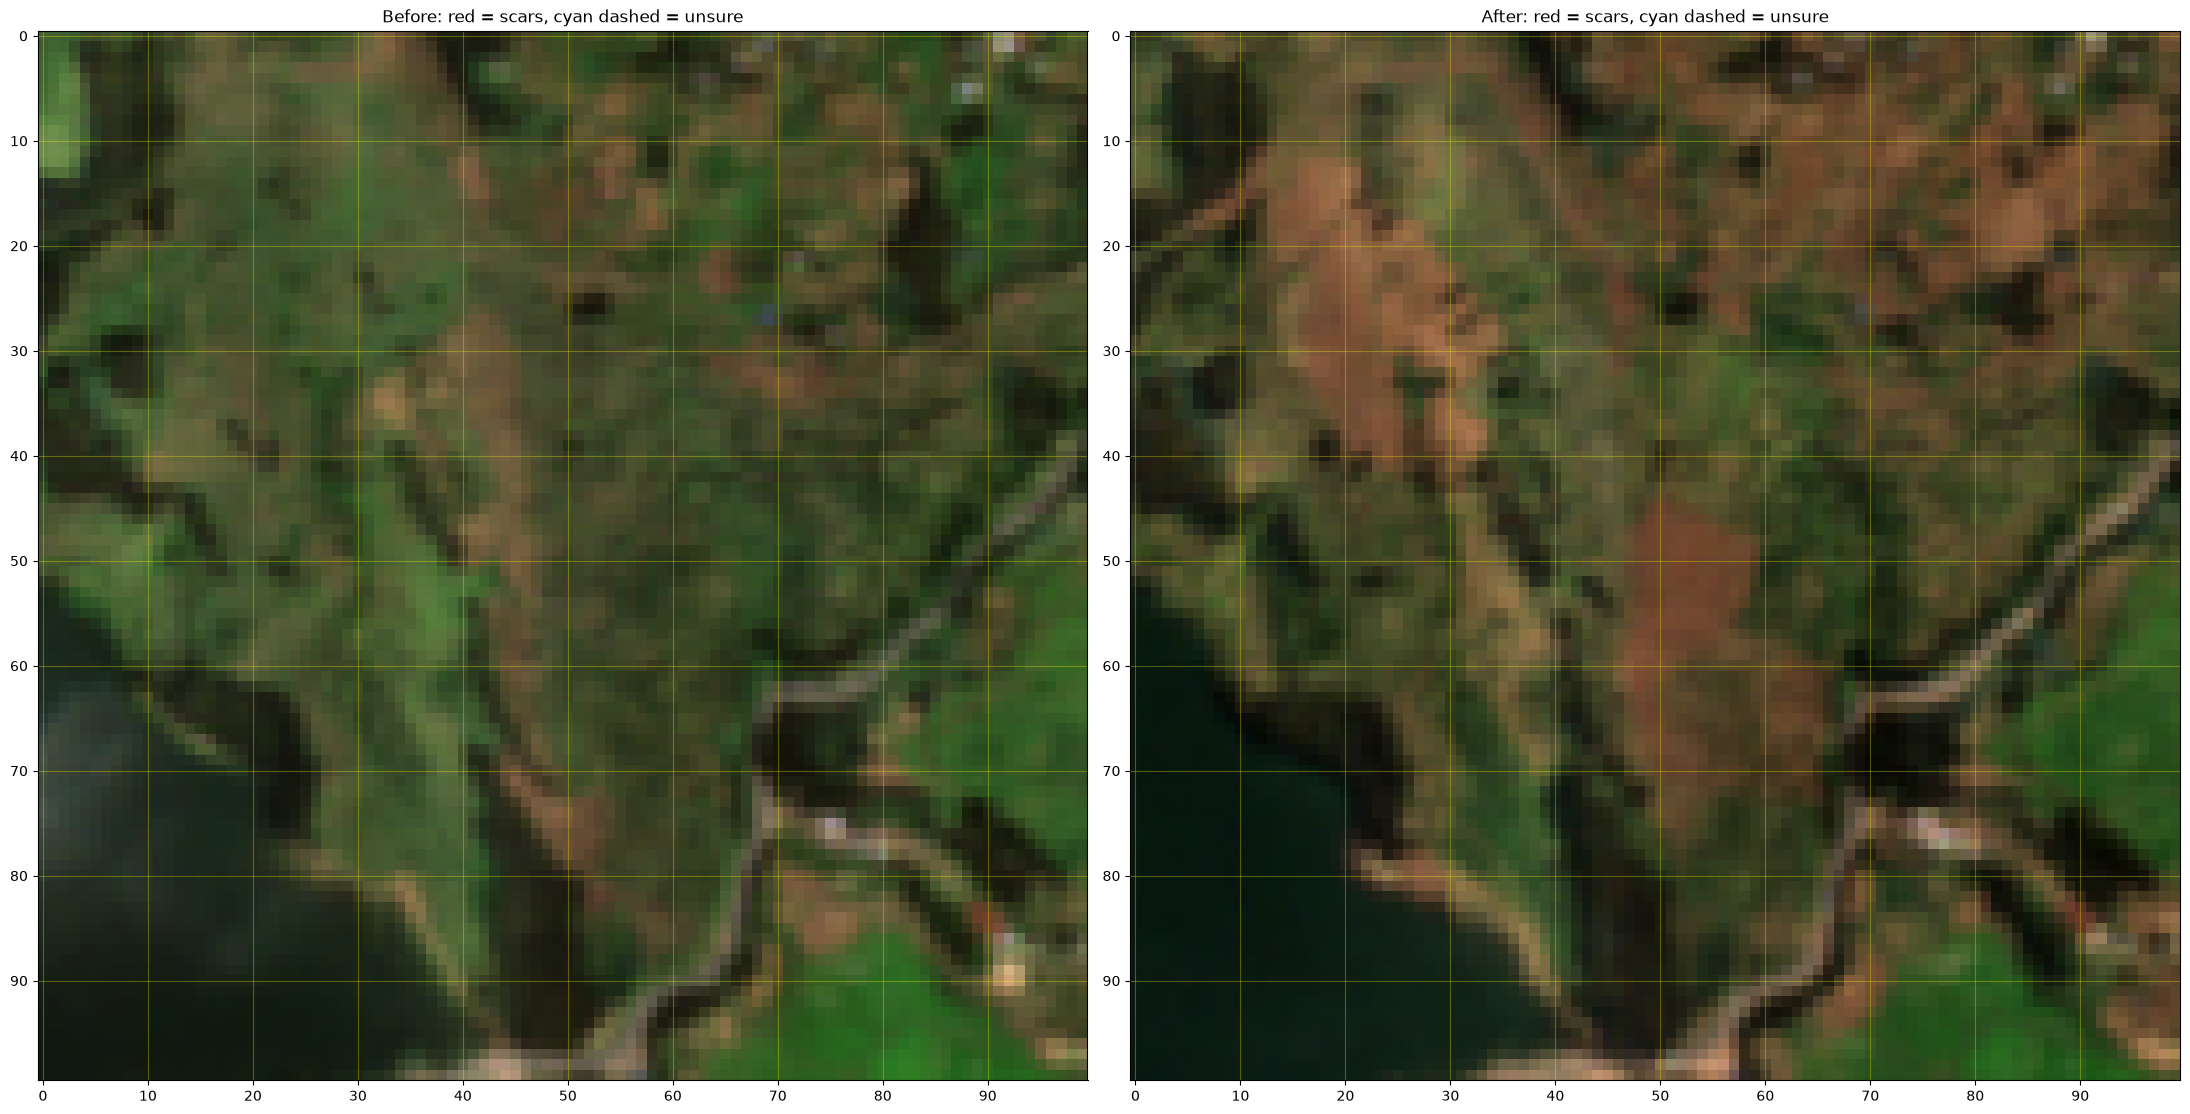

In [13]:
from skimage.draw import polygon

scar_polys = [
    # one list per scar, corners as (row, col). Example shape:
    # [(10, 20), (10, 35), (40, 30), (38, 18)],
]
unsure_polys = [
    # same format, for patches you cannot decide on
]

def rasterize(polys, shape=(100, 100)):
    m = np.zeros(shape, "uint8")
    for p in polys:
        rr, cc = polygon([v[0] for v in p], [v[1] for v in p], shape)
        m[rr, cc] = 1
    return m

hand = rasterize(scar_polys)
unsure = rasterize(unsure_polys)
print("scars:", len(scar_polys), "| labelled pixels:", hand.sum(), "| unsure pixels:", unsure.sum())

fig, axes = plt.subplots(1, 2, figsize=(22, 11))
for ax, date in zip(axes, ["before", "after"]):
    ax.imshow(true_colour(date)[r0:r0 + 100, c0:c0 + 100], interpolation="nearest")
    for i, p in enumerate(scar_polys):
        ys = [v[0] for v in p] + [p[0][0]]; xs = [v[1] for v in p] + [p[0][1]]
        ax.plot(xs, ys, color="red", lw=2)
        ax.text(xs[0], ys[0], str(i + 1), color="white", fontsize=14, weight="bold")
    for p in unsure_polys:
        ys = [v[0] for v in p] + [p[0][0]]; xs = [v[1] for v in p] + [p[0][1]]
        ax.plot(xs, ys, color="cyan", lw=2, ls="--")
    ax.set_xticks(range(0, 100, 10)); ax.set_yticks(range(0, 100, 10)); ax.grid(color="yellow", alpha=0.3)
    ax.set_title(f"{date.capitalize()}: red = scars, cyan dashed = unsure")
plt.tight_layout(); plt.show()

In [14]:
%pip install ipympl -q

Note: you may need to restart the kernel to use updated packages.


In [15]:
import os, time, rasterio, numpy as np
import matplotlib.pyplot as plt

def read(path):
    with rasterio.open(path) as src:
        return src.read(1).astype("float32")

bands = {}
for date in ["before", "after"]:
    for b in ["B02", "B03", "B04", "B08"]:
        bands[(date, b)] = read(f"data/{date}_{b}.tiff")

def true_colour(date, d=0.2):
    rgb = np.dstack([bands[(date, "B04")], bands[(date, "B03")], bands[(date, "B02")]])
    return np.clip(rgb / d, 0, 1)

t_start = time.time()
print("Labeling started at", time.strftime("%H:%M:%S"))

Labeling started at 13:25:03


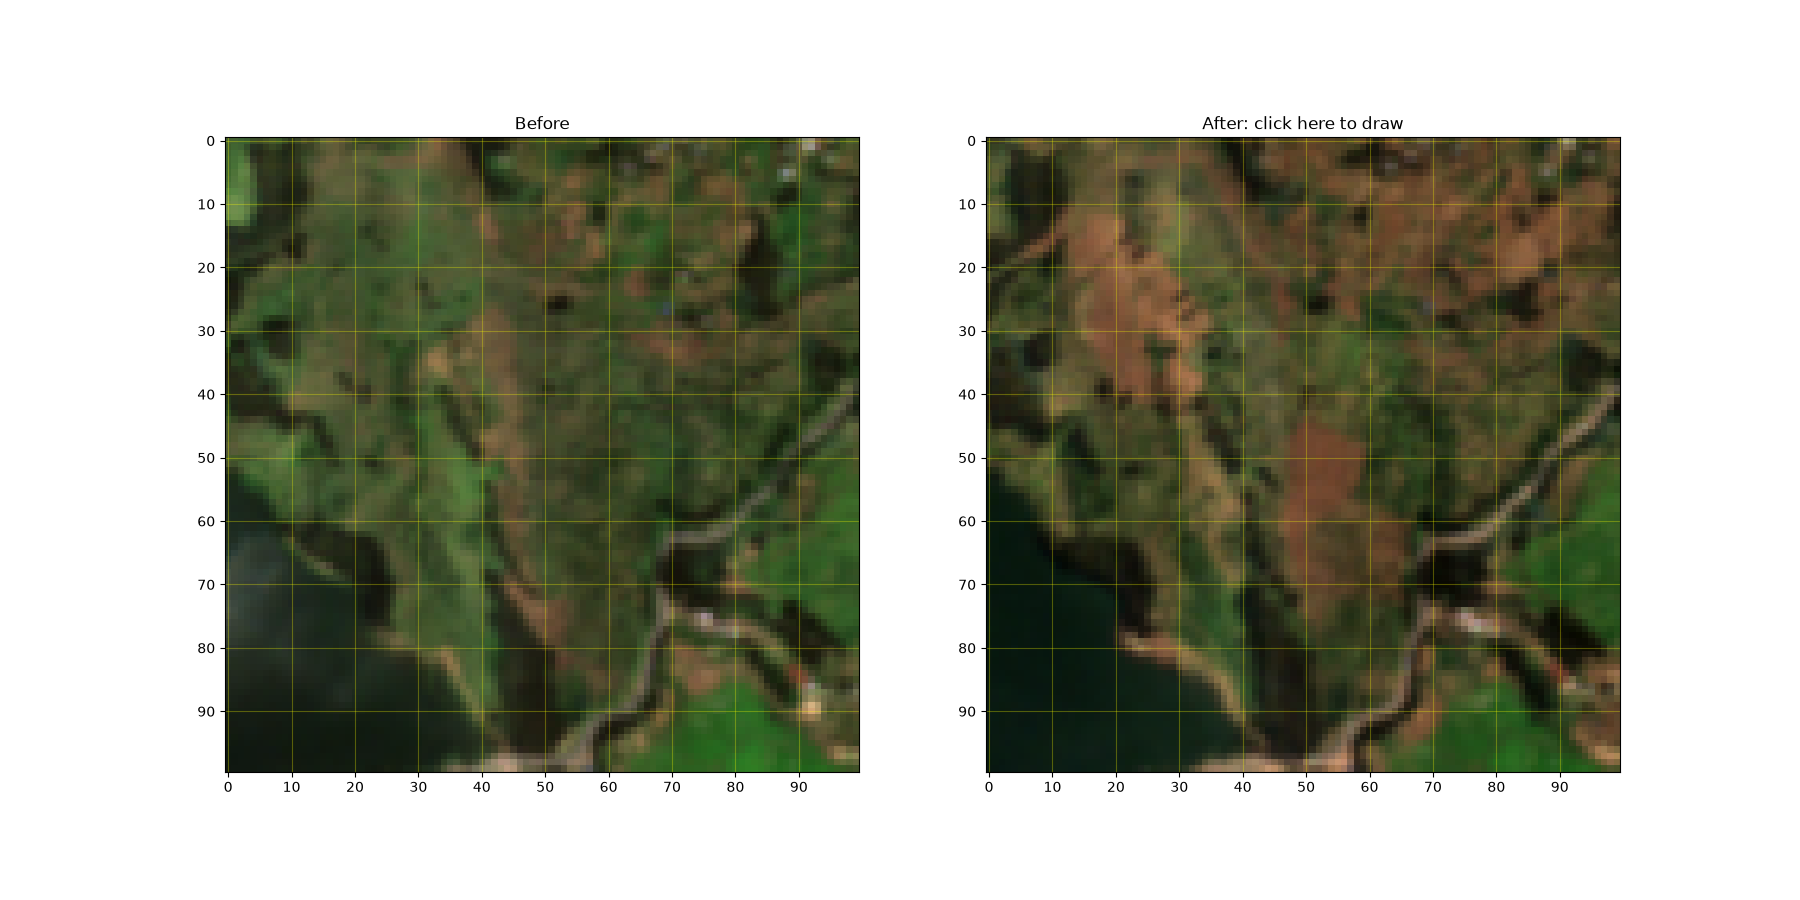

In [16]:
%matplotlib widget
from matplotlib.widgets import PolygonSelector

r0, c0 = 83, 118                      # window E
scar_polys, unsure_polys = [], []
current = {"verts": None}
history = []

fig, axes = plt.subplots(1, 2, figsize=(18, 9))
for ax, date in zip(axes, ["before", "after"]):
    ax.imshow(true_colour(date)[r0:r0 + 100, c0:c0 + 100], interpolation="nearest")
    ax.set_xticks(range(0, 100, 10)); ax.set_yticks(range(0, 100, 10))
    ax.grid(color="yellow", alpha=0.3)
    ax.set_title(date.capitalize())
axes[1].set_title("After: click here to draw")

def onselect(verts):
    current["verts"] = [(min(max(y, -0.5), 99.5), min(max(x, -0.5), 99.5)) for x, y in verts]

selector = PolygonSelector(axes[1], onselect, useblit=True)

def on_key(event):
    v = current["verts"]
    if event.key in ("enter", "u") and v and len(v) >= 3:
        is_scar = event.key == "enter"
        (scar_polys if is_scar else unsure_polys).append(v)
        ys = [p[0] for p in v] + [v[0][0]]; xs = [p[1] for p in v] + [v[0][1]]
        lines = [ax.plot(xs, ys, color="red" if is_scar else "cyan", lw=2)[0] for ax in axes]
        history.append((scar_polys if is_scar else unsure_polys, lines))
        current["verts"] = None
        try: selector.clear()
        except Exception: pass
        print("scars:", len(scar_polys), "| unsure:", len(unsure_polys))
    elif event.key == "d" and history:
        lst, lines = history.pop(); lst.pop()
        for l in lines: l.remove()
        print("scars:", len(scar_polys), "| unsure:", len(unsure_polys))

fig.canvas.mpl_connect("key_press_event", on_key)
plt.show()

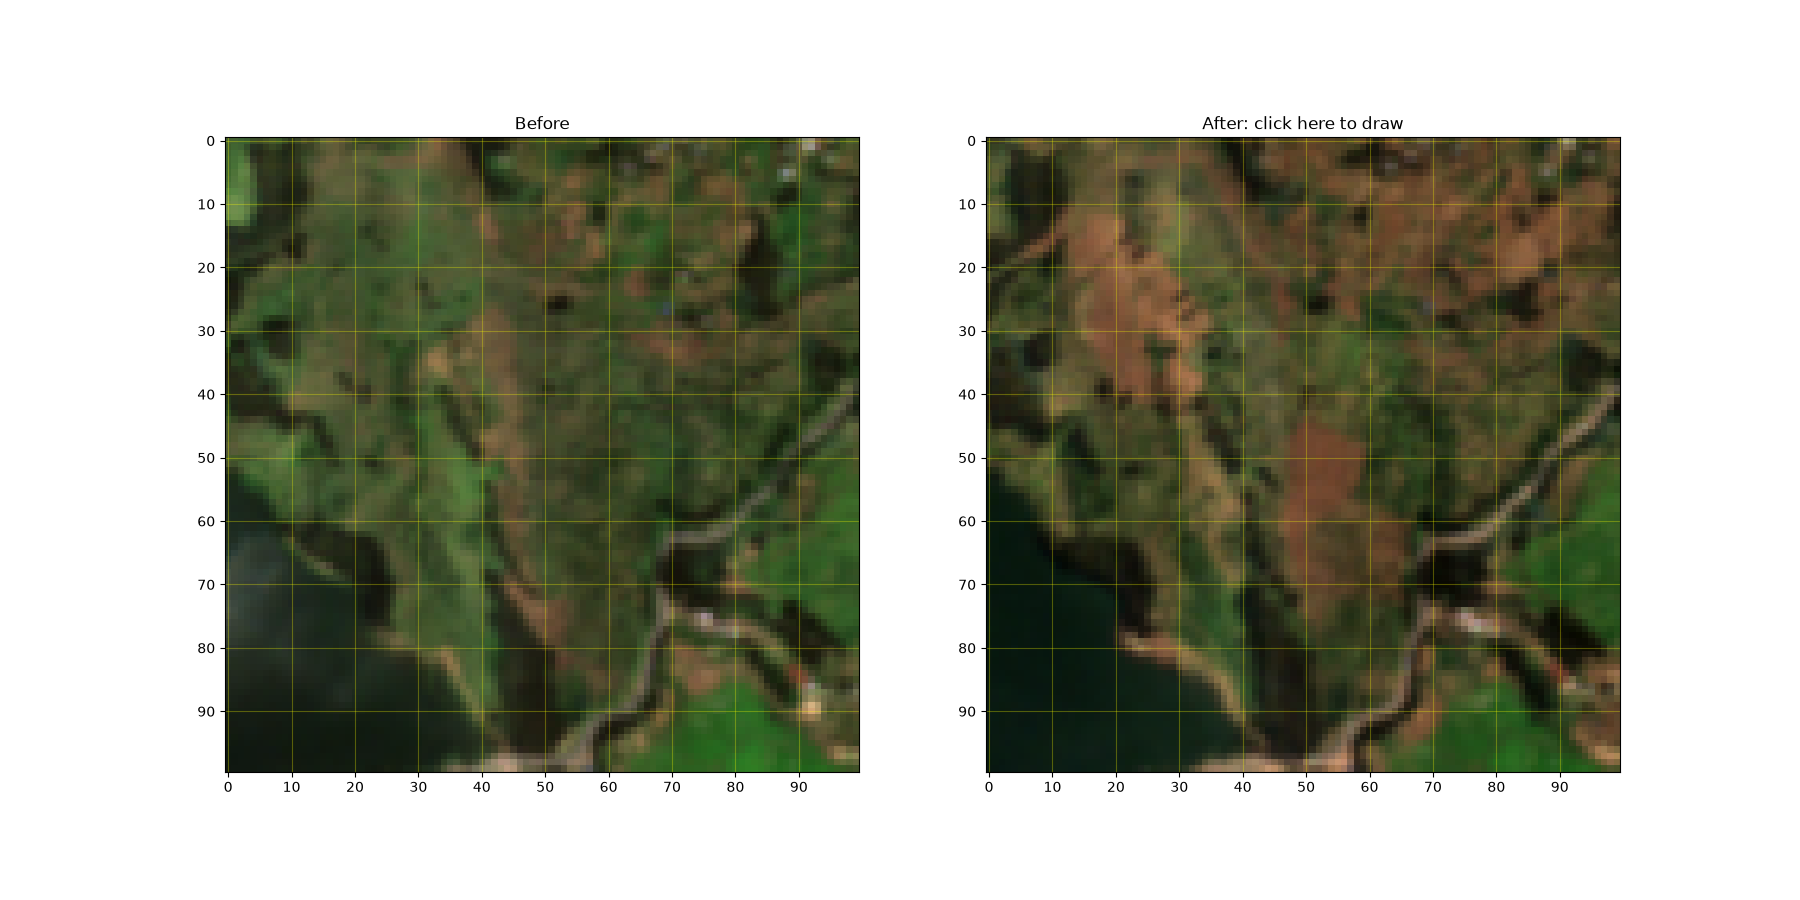

scars: 1 | unsure: 0
scars: 2 | unsure: 0
scars: 3 | unsure: 0
scars: 4 | unsure: 0
scars: 5 | unsure: 0
scars: 6 | unsure: 0
scars: 7 | unsure: 0


In [17]:
%matplotlib tk
from matplotlib.widgets import PolygonSelector

r0, c0 = 83, 118                      # window E
scar_polys, unsure_polys = [], []
current = {"verts": None}
history = []

fig, axes = plt.subplots(1, 2, figsize=(18, 9))
for ax, date in zip(axes, ["before", "after"]):
    ax.imshow(true_colour(date)[r0:r0 + 100, c0:c0 + 100], interpolation="nearest")
    ax.set_xticks(range(0, 100, 10)); ax.set_yticks(range(0, 100, 10))
    ax.grid(color="yellow", alpha=0.3)
    ax.set_title(date.capitalize())
axes[1].set_title("After: click here to draw")

def onselect(verts):
    current["verts"] = [(min(max(y, -0.5), 99.5), min(max(x, -0.5), 99.5)) for x, y in verts]

selector = PolygonSelector(axes[1], onselect, useblit=True)

def on_key(event):
    v = current["verts"]
    if event.key in ("enter", "u") and v and len(v) >= 3:
        is_scar = event.key == "enter"
        (scar_polys if is_scar else unsure_polys).append(v)
        ys = [p[0] for p in v] + [v[0][0]]; xs = [p[1] for p in v] + [v[0][1]]
        lines = [ax.plot(xs, ys, color="red" if is_scar else "cyan", lw=2)[0] for ax in axes]
        history.append((scar_polys if is_scar else unsure_polys, lines))
        current["verts"] = None
        try: selector.clear()
        except Exception: pass
        fig.canvas.draw_idle()
        print("scars:", len(scar_polys), "| unsure:", len(unsure_polys))
    elif event.key == "d" and history:
        lst, lines = history.pop(); lst.pop()
        for l in lines: l.remove()
        fig.canvas.draw_idle()
        print("scars:", len(scar_polys), "| unsure:", len(unsure_polys))

fig.canvas.mpl_connect("key_press_event", on_key)
plt.show()

scars: 7 | labelled pixels: 1953 | unsure: 0 shapes, 0 pixels
Time since setup cell: 17.1 minutes


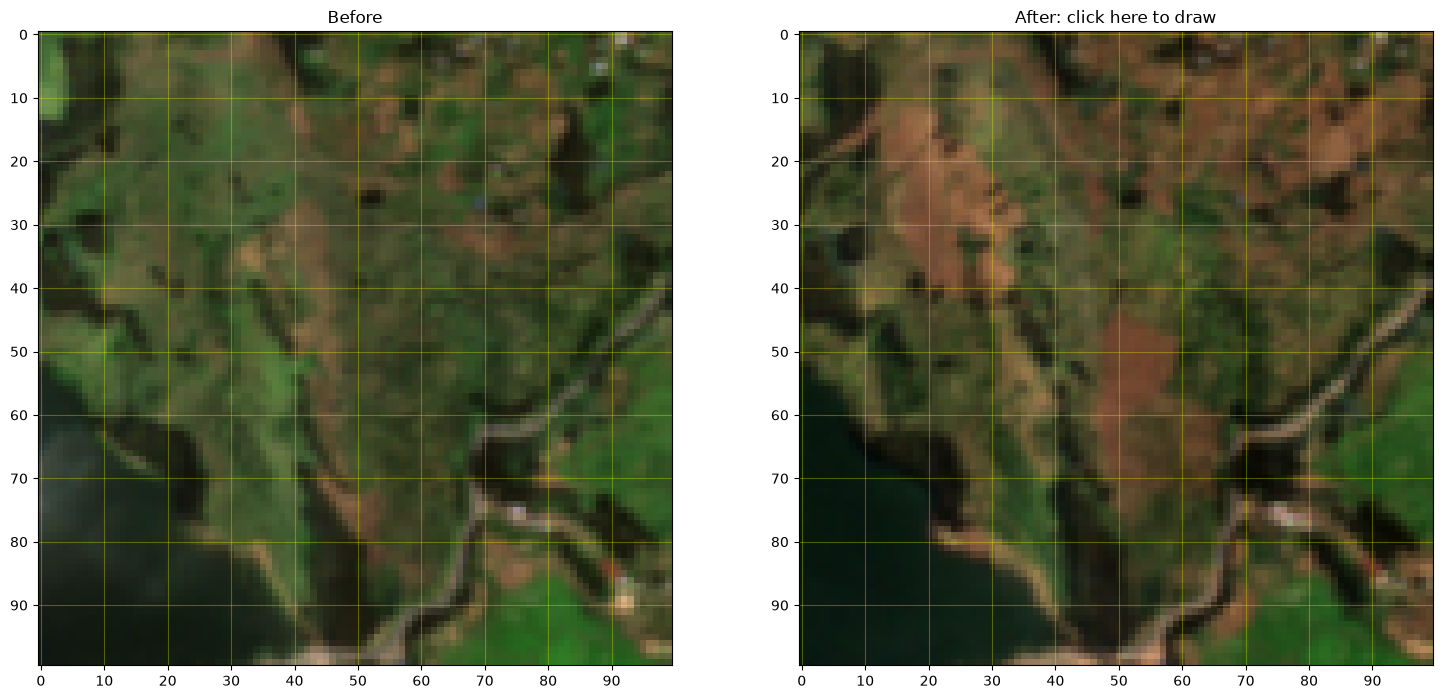

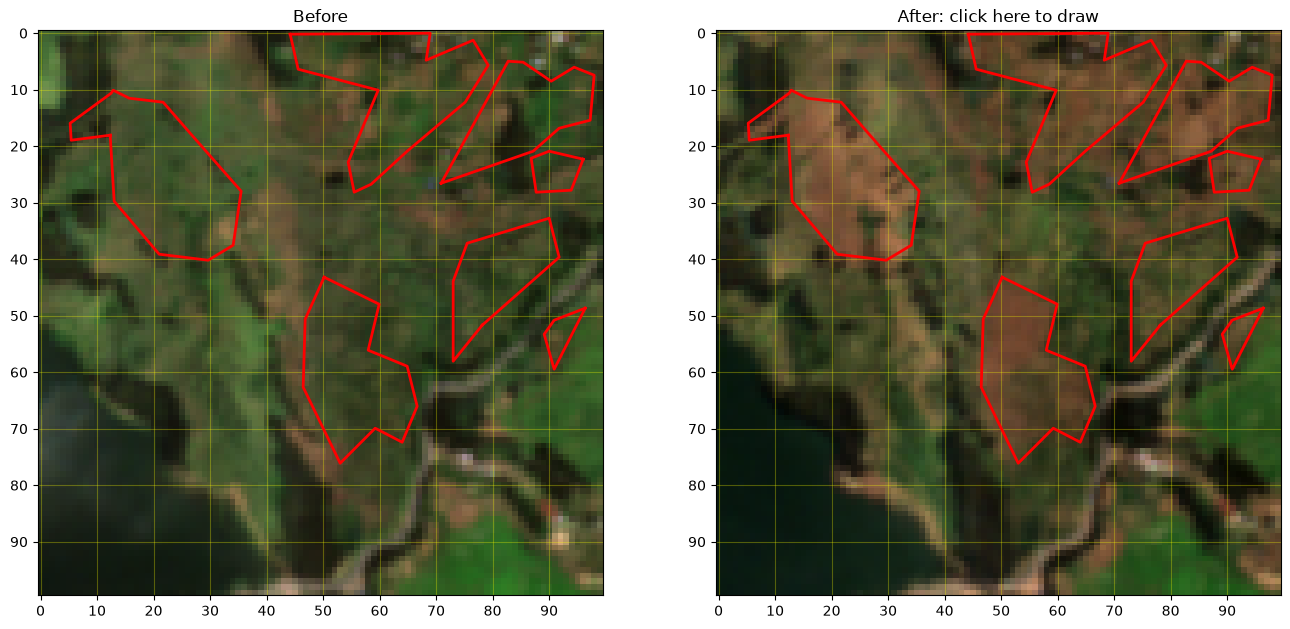

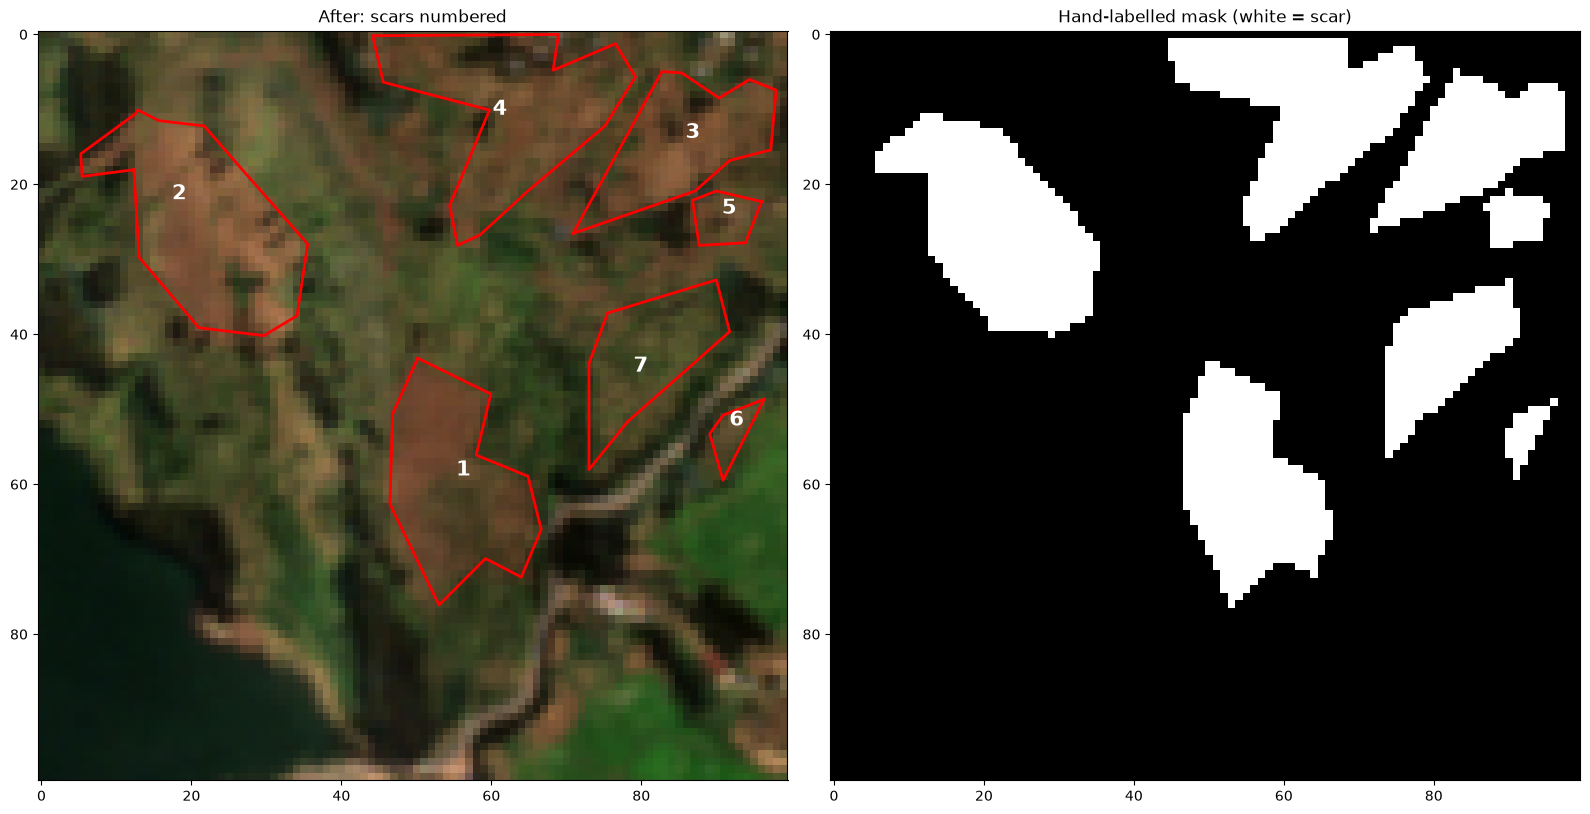

In [18]:
%matplotlib inline
from skimage.draw import polygon

def rasterize(polys, shape=(100, 100)):
    m = np.zeros(shape, "uint8")
    for p in polys:
        rr, cc = polygon([v[0] for v in p], [v[1] for v in p], shape)
        m[rr, cc] = 1
    return m

hand = rasterize(scar_polys)
unsure = rasterize(unsure_polys)
print("scars:", len(scar_polys), "| labelled pixels:", hand.sum(), "| unsure:", len(unsure_polys), "shapes,", unsure.sum(), "pixels")
print("Time since setup cell:", round((time.time() - t_start) / 60, 1), "minutes")

fig2, ax2 = plt.subplots(1, 2, figsize=(16, 8))
ax2[0].imshow(true_colour("after")[r0:r0 + 100, c0:c0 + 100], interpolation="nearest")
for i, p in enumerate(scar_polys):
    ys = [v[0] for v in p] + [p[0][0]]; xs = [v[1] for v in p] + [p[0][1]]
    ax2[0].plot(xs, ys, color="red", lw=2)
    ax2[0].text(np.mean(xs), np.mean(ys), str(i + 1), color="white", fontsize=15, weight="bold", ha="center")
for p in unsure_polys:
    ys = [v[0] for v in p] + [p[0][0]]; xs = [v[1] for v in p] + [p[0][1]]
    ax2[0].plot(xs, ys, color="cyan", lw=2, ls="--")
ax2[0].set_title("After: scars numbered")
ax2[1].imshow(hand, cmap="gray"); ax2[1].set_title("Hand-labelled mask (white = scar)")
plt.tight_layout(); plt.show()

In [19]:
move_to_unsure = [2, 3, 4]      # numbers shown in the figure

for n in sorted(move_to_unsure, reverse=True):
    unsure_polys.append(scar_polys.pop(n - 1))

print("scars:", len(scar_polys), "| unsure:", len(unsure_polys))

scars: 4 | unsure: 3


scars: 4 | labelled pixels: 711 | unsure: 3 shapes, 1242 pixels


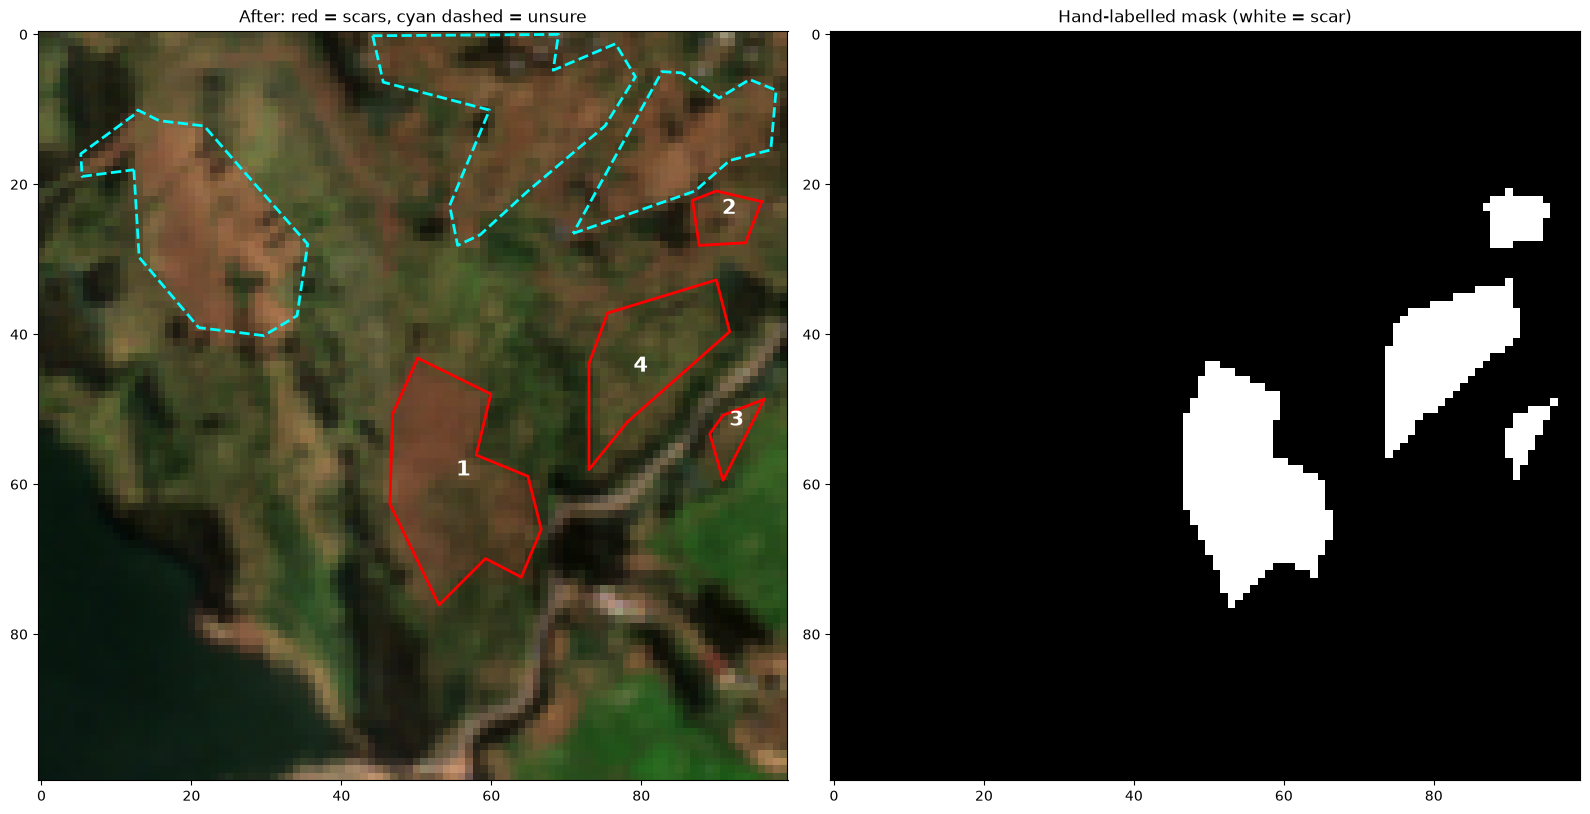

In [20]:
%matplotlib inline
from skimage.draw import polygon

def rasterize(polys, shape=(100, 100)):
    m = np.zeros(shape, "uint8")
    for p in polys:
        rr, cc = polygon([v[0] for v in p], [v[1] for v in p], shape)
        m[rr, cc] = 1
    return m

hand = rasterize(scar_polys)
unsure = rasterize(unsure_polys)
print("scars:", len(scar_polys), "| labelled pixels:", hand.sum(), "| unsure:", len(unsure_polys), "shapes,", unsure.sum(), "pixels")

fig2, ax2 = plt.subplots(1, 2, figsize=(16, 8))
ax2[0].imshow(true_colour("after")[r0:r0 + 100, c0:c0 + 100], interpolation="nearest")
for i, p in enumerate(scar_polys):
    ys = [v[0] for v in p] + [p[0][0]]; xs = [v[1] for v in p] + [p[0][1]]
    ax2[0].plot(xs, ys, color="red", lw=2)
    ax2[0].text(np.mean(xs), np.mean(ys), str(i + 1), color="white", fontsize=15, weight="bold", ha="center")
for p in unsure_polys:
    ys = [v[0] for v in p] + [p[0][0]]; xs = [v[1] for v in p] + [p[0][1]]
    ax2[0].plot(xs, ys, color="cyan", lw=2, ls="--")
ax2[0].set_title("After: red = scars, cyan dashed = unsure")
ax2[1].imshow(hand, cmap="gray"); ax2[1].set_title("Hand-labelled mask (white = scar)")
plt.tight_layout(); plt.show()

In [21]:
import json
from rasterio.windows import Window
from PIL import Image

os.makedirs("out", exist_ok=True)

with rasterio.open("data/before_B04.tiff") as src:
    profile = src.profile.copy()
    transform = src.window_transform(Window(c0, r0, 100, 100))
profile.update(count=1, dtype="uint8", width=100, height=100, transform=transform, nodata=None)

for name, arr in [("hand_mask", hand), ("unsure_mask", unsure)]:
    with rasterio.open(f"out/{name}.tif", "w", **profile) as dst:
        dst.write(arr, 1)
    Image.fromarray(arr * 255).save(f"out/{name}.png")

# backup of your polygons, in case the kernel restarts
with open("out/polygons.json", "w") as f:
    json.dump({"window_r0_c0": [r0, c0], "scars": scar_polys, "unsure": unsure_polys}, f)

print(sorted(os.listdir("out")))

['after_window_rgb.tif', 'before_window_rgb.tif', 'hand_mask.png', 'hand_mask.tif', 'polygons.json', 'unsure_mask.png', 'unsure_mask.tif']


In [22]:
with rasterio.open("data/before_B04.tiff") as src:
    b = src.bounds
print("Centre lat, lon:", round((b.top + b.bottom) / 2, 5), round((b.left + b.right) / 2, 5))

Centre lat, lon: -1.61733 29.49005


In [23]:
from skimage.morphology import remove_small_objects

ndvi = lambda nir, red: (nir - red) / (nir + red + 1e-6)
ndvi_b = ndvi(bands[("before", "B08")], bands[("before", "B04")])
ndvi_a = ndvi(bands[("after", "B08")], bands[("after", "B04")])
dndvi = ndvi_a - ndvi_b

def clean(m, min_px=5):
    try:
        return remove_small_objects(m.astype(bool), max_size=min_px - 1).astype("uint8")
    except TypeError:
        return remove_small_objects(m.astype(bool), min_size=min_px).astype("uint8")

thresholds = [-0.2, -0.3, -0.4]
raw_masks   = {t: (dndvi < t).astype("uint8") for t in thresholds}
ruled_masks = {t: clean((dndvi < t) & (ndvi_b > 0.5)) for t in thresholds}

win = (slice(r0, r0 + 100), slice(c0, c0 + 100))     # the same 100 x 100 window as your labels
gt = hand.astype(bool)
ignore = unsure.astype(bool)

def scores(pred, gt, ignore=None):
    if ignore is not None:
        keep = ~ignore
        pred, gt = pred[keep], gt[keep]
    tp = int((pred & gt).sum()); fp = int((pred & ~gt).sum()); fn = int((~pred & gt).sum())
    iou  = tp / (tp + fp + fn) if (tp + fp + fn) else 0.0
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec  = tp / (tp + fn) if (tp + fn) else 0.0
    return tp, fp, fn, iou, prec, rec

rows = []
for kind, masks in [("with rule", ruled_masks), ("raw", raw_masks)]:
    for t in thresholds:
        pred = masks[t][win].astype(bool)
        tp, fp, fn, iou, p, r = scores(pred, gt)
        iou_u = scores(pred, gt, ignore)[3]
        rows.append({"mask": kind, "threshold": t, "TP": tp, "FP": fp, "FN": fn,
                     "IoU": round(iou, 3), "precision": round(p, 3), "recall": round(r, 3),
                     "IoU (unsure ignored)": round(iou_u, 3)})

import pandas as pd
table = pd.DataFrame(rows)
print(table.to_string(index=False))
table.to_csv("out/metrics.csv", index=False)

best = max([r for r in rows if r["mask"] == "with rule"], key=lambda r: r["IoU"])
print("\nBest threshold (with rule):", best["threshold"], "| IoU:", best["IoU"])

     mask  threshold  TP   FP  FN   IoU  precision  recall  IoU (unsure ignored)
with rule       -0.2 284 1032 427 0.163      0.216   0.399                 0.299
with rule       -0.3 188  585 523 0.145      0.243   0.264                 0.248
with rule       -0.4 103  353 608 0.097      0.226   0.145                 0.144
      raw       -0.2 286 1874 425 0.111      0.132   0.402                 0.161
      raw       -0.3 190 1323 521 0.093      0.126   0.267                 0.130
      raw       -0.4 107  990 604 0.063      0.098   0.150                 0.080

Best threshold (with rule): -0.2 | IoU: 0.163


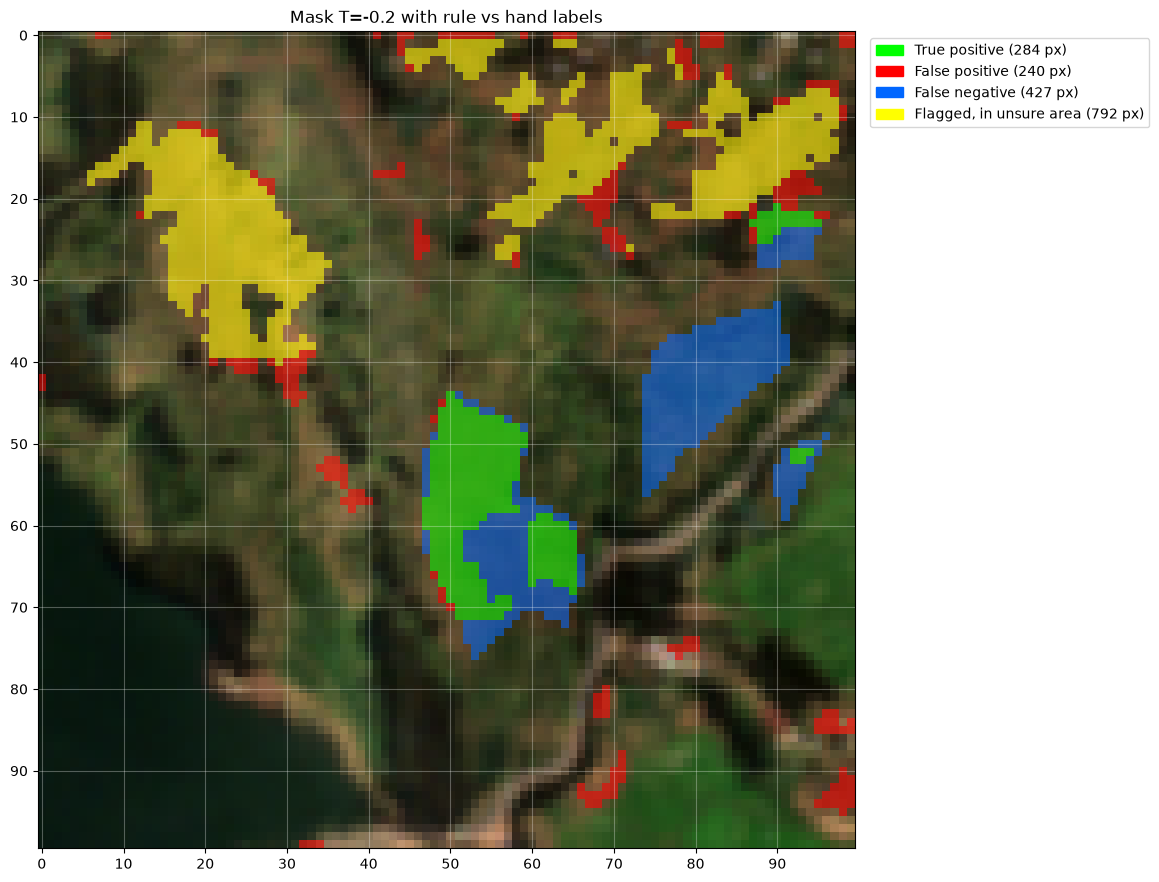

In [24]:
import matplotlib.patches as mpatches

BEST_T = -0.2
pred = ruled_masks[BEST_T][win].astype(bool)
base = true_colour("after")[r0:r0 + 100, c0:c0 + 100]

cats = [("True positive", pred & gt, [0, 1, 0]),
        ("False positive", pred & ~gt & ~ignore, [1, 0, 0]),
        ("False negative", ~pred & gt, [0, 0.4, 1]),
        ("Flagged, in unsure area", pred & ignore & ~gt, [1, 1, 0])]

ov = base.copy()
for name, m, col in cats:
    ov[m] = 0.45 * base[m] + 0.55 * np.array(col)

fig, ax = plt.subplots(figsize=(11, 10))
ax.imshow(ov, interpolation="nearest")
ax.set_xticks(range(0, 100, 10)); ax.set_yticks(range(0, 100, 10)); ax.grid(color="white", alpha=0.3)
ax.legend(handles=[mpatches.Patch(color=col, label=f"{name} ({int(m.sum())} px)") for name, m, col in cats],
          loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title(f"Mask T={BEST_T} with rule vs hand labels")
plt.tight_layout(); plt.show()

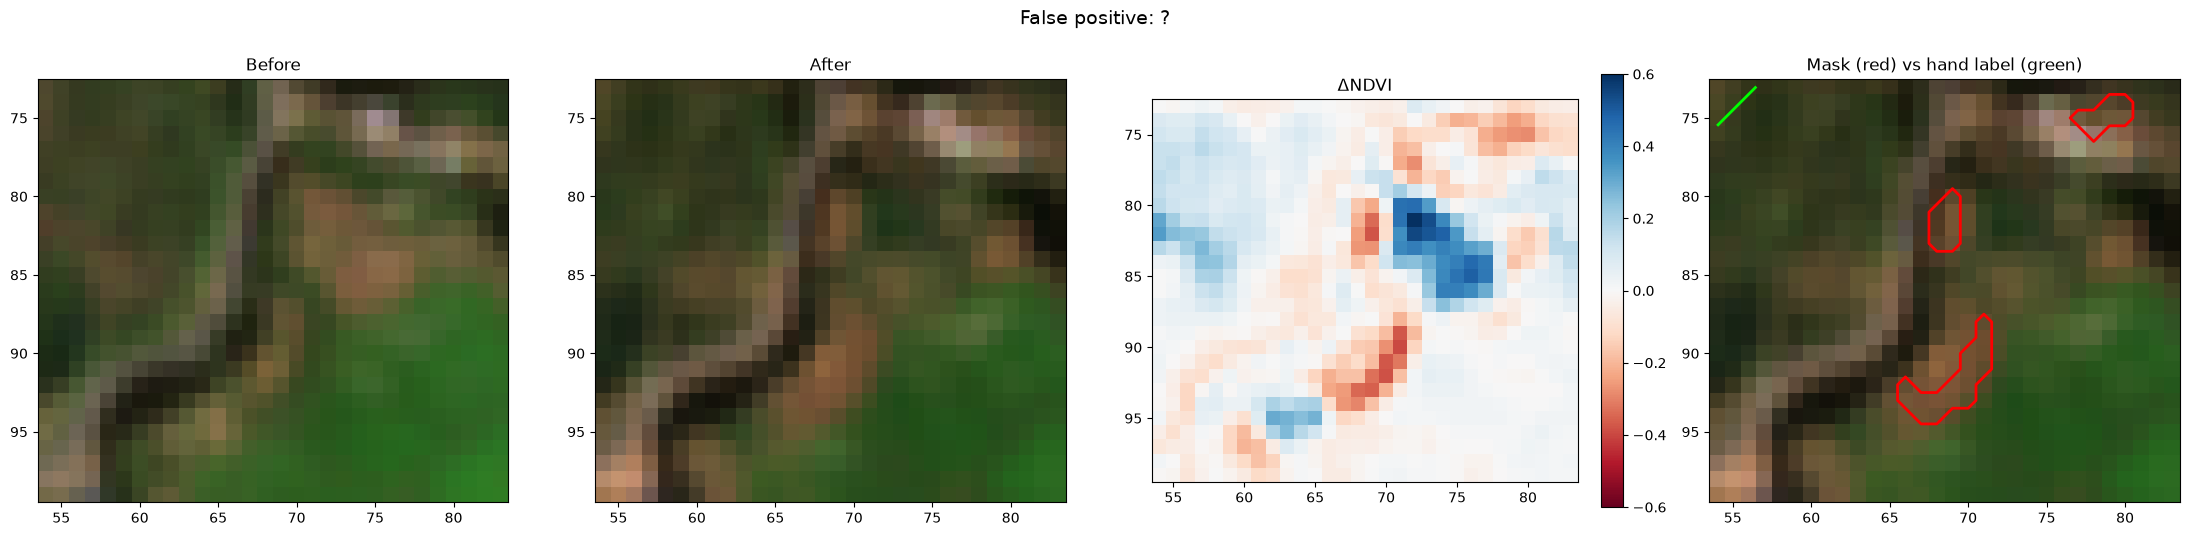

False positive: ?
  NDVI before 0.64 | after 0.66 | ΔNDVI 0.01 | mask covers 4% of box | hand label covers 1%


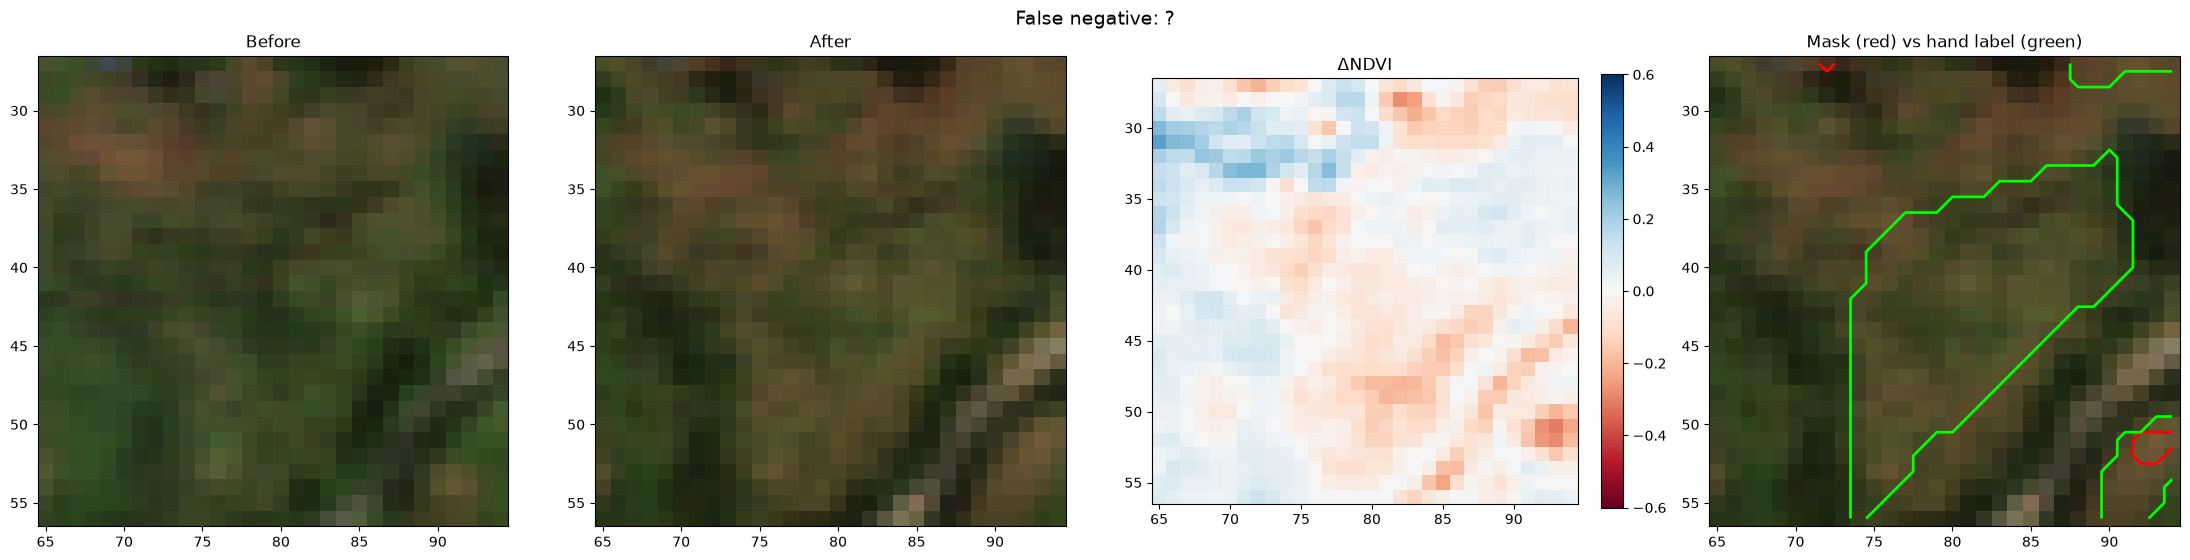

False negative: ?
  NDVI before 0.68 | after 0.67 | ΔNDVI -0.01 | mask covers 1% of box | hand label covers 29%


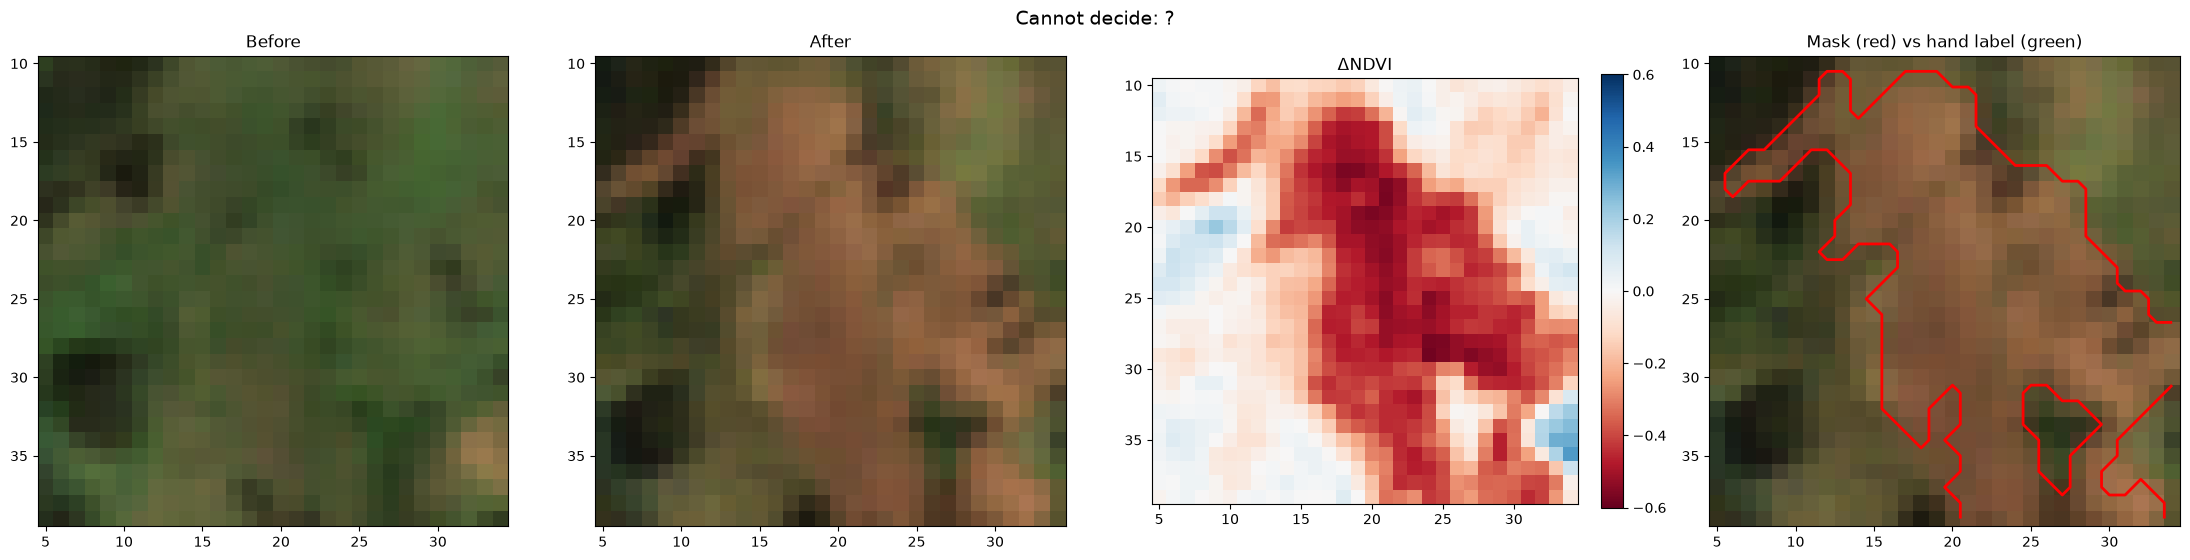

Cannot decide: ?
  NDVI before 0.66 | after 0.45 | ΔNDVI -0.20 | mask covers 44% of box | hand label covers 0%


In [25]:
def show_case(title, row, col, half=15):
    ra, rb = max(row - half, 0), min(row + half, 100)
    ca, cb = max(col - half, 0), min(col + half, 100)
    R, C = slice(r0 + ra, r0 + rb), slice(c0 + ca, c0 + cb)
    ext = (ca - 0.5, cb - 0.5, rb - 0.5, ra - 0.5)
    pred = ruled_masks[BEST_T][win].astype(bool)

    fig, ax = plt.subplots(1, 4, figsize=(22, 5.5))
    ax[0].imshow(true_colour("before")[R, C], extent=ext, interpolation="nearest"); ax[0].set_title("Before")
    ax[1].imshow(true_colour("after")[R, C], extent=ext, interpolation="nearest"); ax[1].set_title("After")
    im = ax[2].imshow(dndvi[R, C], cmap="RdBu", vmin=-0.6, vmax=0.6, extent=ext, interpolation="nearest")
    ax[2].set_title("ΔNDVI"); plt.colorbar(im, ax=ax[2], fraction=0.046)
    ax[3].imshow(true_colour("after")[R, C], extent=ext, interpolation="nearest")
    xs, ys = np.arange(ca, cb), np.arange(ra, rb)
    for arr, colr in [(pred, "red"), (gt, "lime")]:
        sub = arr[ra:rb, ca:cb].astype(float)
        if sub.min() != sub.max():
            ax[3].contour(xs, ys, sub, levels=[0.5], colors=colr, linewidths=2)
    ax[3].set_title("Mask (red) vs hand label (green)")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout(); plt.show()

    sl = (slice(ra, rb), slice(ca, cb))
    print(f"{title}\n  NDVI before {ndvi_b[win][sl].mean():.2f} | after {ndvi_a[win][sl].mean():.2f} | "
          f"ΔNDVI {dndvi[win][sl].mean():.2f} | mask covers {pred[sl].mean():.0%} of box | "
          f"hand label covers {gt[sl].mean():.0%}")

BEST_T = -0.2
show_case("False positive: ?", 88, 69)
show_case("False negative: ?", 42, 80)
show_case("Cannot decide: ?", 25, 20)

In [26]:
pred = ruled_masks[BEST_T][win].astype(bool)
nb, na, dd = ndvi_b[win], ndvi_a[win], dndvi[win]

def region_stats(name, row, col, half, sel):
    box = np.zeros((100, 100), bool)
    box[max(row - half, 0):row + half, max(col - half, 0):col + half] = True
    s = sel & box
    if s.sum() == 0:
        print(f"{name}: no pixels of this type in the box"); return
    print(f"{name}: {s.sum()} px | NDVI before {nb[s].mean():.2f} | after {na[s].mean():.2f} | ΔNDVI {dd[s].mean():.2f}")

region_stats("False positive", 88, 69, 15, pred & ~gt & ~ignore)
region_stats("False negative", 42, 80, 15, gt & ~pred)
region_stats("Cannot decide", 25, 20, 15, pred & ignore)

False positive: 30 px | NDVI before 0.67 | after 0.39 | ΔNDVI -0.28
False negative: 256 px | NDVI before 0.68 | after 0.65 | ΔNDVI -0.04
Cannot decide: 381 px | NDVI before 0.65 | after 0.24 | ΔNDVI -0.41


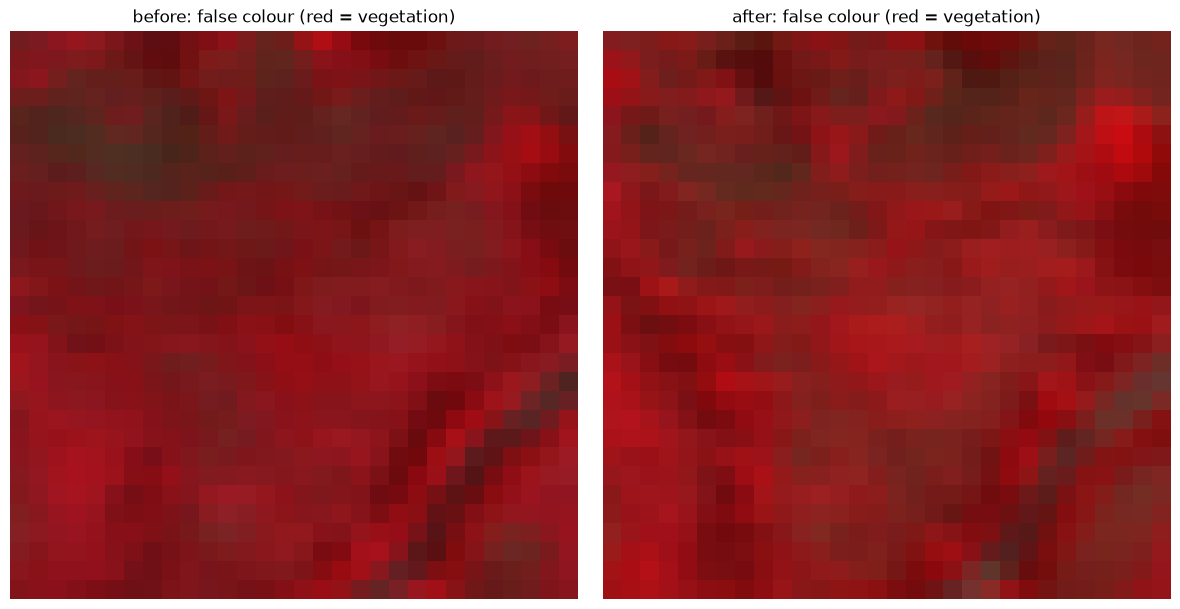

In [27]:
fc = lambda d: np.clip(np.dstack([bands[(d, "B08")], bands[(d, "B04")], bands[(d, "B03")]]) / 0.5, 0, 1)
rr, cc = slice(r0 + 27, r0 + 57), slice(c0 + 65, c0 + 95)       # around row 42, col 80
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
for a, d in zip(ax, ["before", "after"]):
    a.imshow(fc(d)[rr, cc], interpolation="nearest"); a.set_title(f"{d}: false colour (red = vegetation)"); a.axis("off")
plt.tight_layout(); plt.show()

Failure cases (window E, mask T=-0.2 with rule)

1. False positive (around row 88, col 69).** 30 px flagged but not labelled. NDVI fell from 0.67 to 0.39 (ΔNDVI -0.28). Cause: ____ (my own reading of the before/after picture).

2. **2. False negative (around row 42, col 80).** 256 labelled px missed. NDVI stayed at 0.68 → 0.65 (ΔNDVI -0.04), so the threshold could not see it. A false-colour check showed dense vegetation (red) in both dates. Cause: the colour change in true colour is not a vegetation loss, so my label there is probably wrong (dry or senescent cover, or different lighting between January and July).

3. Cannot decide (around row 25, col 20).** 381 px in my unsure area, flagged by the mask. NDVI fell from 0.65 to 0.24 (ΔNDVI -0.41). It is large, blocky and tan, so it could be a harvested field or a scar. NDVI cannot tell which.

## Reflection

A single pixel rule sees only one number per pixel: how much NDVI changed. In my window, the best mask (ΔNDVI < -0.2, NDVI_before > 0.5, small blobs removed) reached IoU 0.163, with precision 0.216 and recall 0.399. About four in five flagged pixels were wrong, and it found only 40% of my labelled scar pixels.

The rule cannot tell why vegetation changed. A large tan patch lost most of its NDVI (0.65 to 0.24), but it could be a harvested field or a scar, and I could not decide either. My images are six months apart (January and July), so seasonal change adds many false alarms. A stricter threshold did not fix this: from -0.2 to -0.4, precision stayed near 0.22 while recall fell from 0.40 to 0.15.

The rule also misses changes that show in colour but not in NDVI. One missed area of 256 labelled pixels had NDVI 0.68 before and 0.65 after.A false-colour check showed dense vegetation in both dates, so the change I saw in true colour was probably not a loss of vegetation and my label there is doubtful. Labelling by eye took 25 minutes and was subjective, so I cannot be sure.

A learned model needs more than one pixel value:
- **Shape and texture:** scars are long and narrow with sharp edges, fields are regular blocks, roads are thin lines.
- **Neighbouring pixels:** a flagged pixel inside a larger bare patch is more believable than an isolated one.
- **Slope:** landslides happen on steep ground, not on flat valley floors.
- **More bands and dates:** these help separate bare soil from dry crops.

A U-Net can learn these cues from labelled examples such as my mask.